# Solar forecast from a weather forecast

1. Take the **irradiance forecast** (W/m²) a weather model issued `LEAD` days before.
2. Convert it to **forecast solar power**: P = k · G.
3. Take the **actual irradiance** for the same hours (ERA5) and convert it the same way → **actual solar power**.
4. Compare the two, plus the boat's measured solar (telemetry) for reference.

Runs over the **17 mission days (14–30 Jul 2025)**. Weather is fetched once per day at that day's **median boat position** from the telemetry (shifted positions/dates, used as-is).

**k = η · A = 0.164 m²** (effective area), fixed from `notebooks/09_solar_model.ipynb` Part 4 (average-day method). It is not refitted here.

**Assumption:** "actual solar power" = k × ERA5 irradiance. Positions and dates in the telemetry are shifted, so the real weather at those coordinates is not the weather the boat had. The measured solar is drawn only to show the scale; it is not expected to match hour by hour.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from compare_weather import get, ARCHIVE_URL, PREVIOUS_RUNS_URL   # same folder

plt.rcParams.update({"figure.figsize": (14, 6), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

K = 0.164                         # m², η·A from nb 09 Part 4 (locked)
LEAD = 1                          # forecast issued this many days earlier (1–7)

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a    # W, measured solar in

# one position per day: median of valid fixes (0, 0 = no GPS fix, left out of the median only)
fix = df[(df.latitude_deg != 0) & (df.longitude_deg != 0)]
pos = fix.groupby(fix.t.dt.floor("D"))[["latitude_deg", "longitude_deg"]].median().round(3)
pos.set_axis(pos.index.strftime("%d %b")).T

t,14 Jul,15 Jul,16 Jul,17 Jul,18 Jul,19 Jul,20 Jul,21 Jul,22 Jul,23 Jul,24 Jul,25 Jul,26 Jul,27 Jul,28 Jul,29 Jul,30 Jul
latitude_deg,60.389,60.570,61.175,61.129,61.163,61.333,61.717,61.906,61.854,62.436,62.538,62.369,62.244,62.136,62.073,62.145,62.257
longitude_deg,2.134,1.626,0.852,0.652,0.765,1.060,1.509,1.623,1.867,1.685,1.802,1.853,1.421,2.252,2.495,2.754,3.117


## 1. Forecast and actual irradiance → solar power, day by day

In [2]:
parts = []
for day, (lat, lon) in pos.iterrows():
    q = {"latitude": lat, "longitude": lon, "start_date": f"{day:%Y-%m-%d}", "end_date": f"{day:%Y-%m-%d}", "timezone": "UTC"}
    fc = get(PREVIOUS_RUNS_URL, {**q, "hourly": f"shortwave_radiation_previous_day{LEAD}"})
    act = get(ARCHIVE_URL, {**q, "hourly": "shortwave_radiation", "models": "era5"})
    parts.append(pd.DataFrame({"G_forecast": fc.iloc[:, 0], "G_actual": act["shortwave_radiation"]}))
s = pd.concat(parts)                  # W/m², hourly mean over the hour BEFORE each timestamp

s["P_forecast"] = K * s.G_forecast    # W
s["P_actual"] = K * s.G_actual        # W
s["err"] = s.P_forecast - s.P_actual  # W, forecast − actual

# measured solar on the same hourly convention: per-minute means, then mean of the hour before each timestamp
sm = df.dropna(subset=["P_solar"]).set_index("t").P_solar.resample("1min").mean().dropna()
s["P_measured"] = sm.resample("1h", label="right", closed="right").mean().reindex(s.index)   # NaN = no Starlink that hour
print(f"{len(s)} hours, {s.P_measured.notna().sum()} with measured solar")

408 hours, 191 with measured solar


## 2. Forecast vs actual solar power, whole mission

Top: irradiance (W/m²), forecast issued `LEAD` days before (orange) and ERA5 (black). Bottom: the same × k = solar power (W), plus measured solar (yellow dots, hourly mean, only hours with Starlink). Hourly values over the hour before each timestamp, drawn as steps.

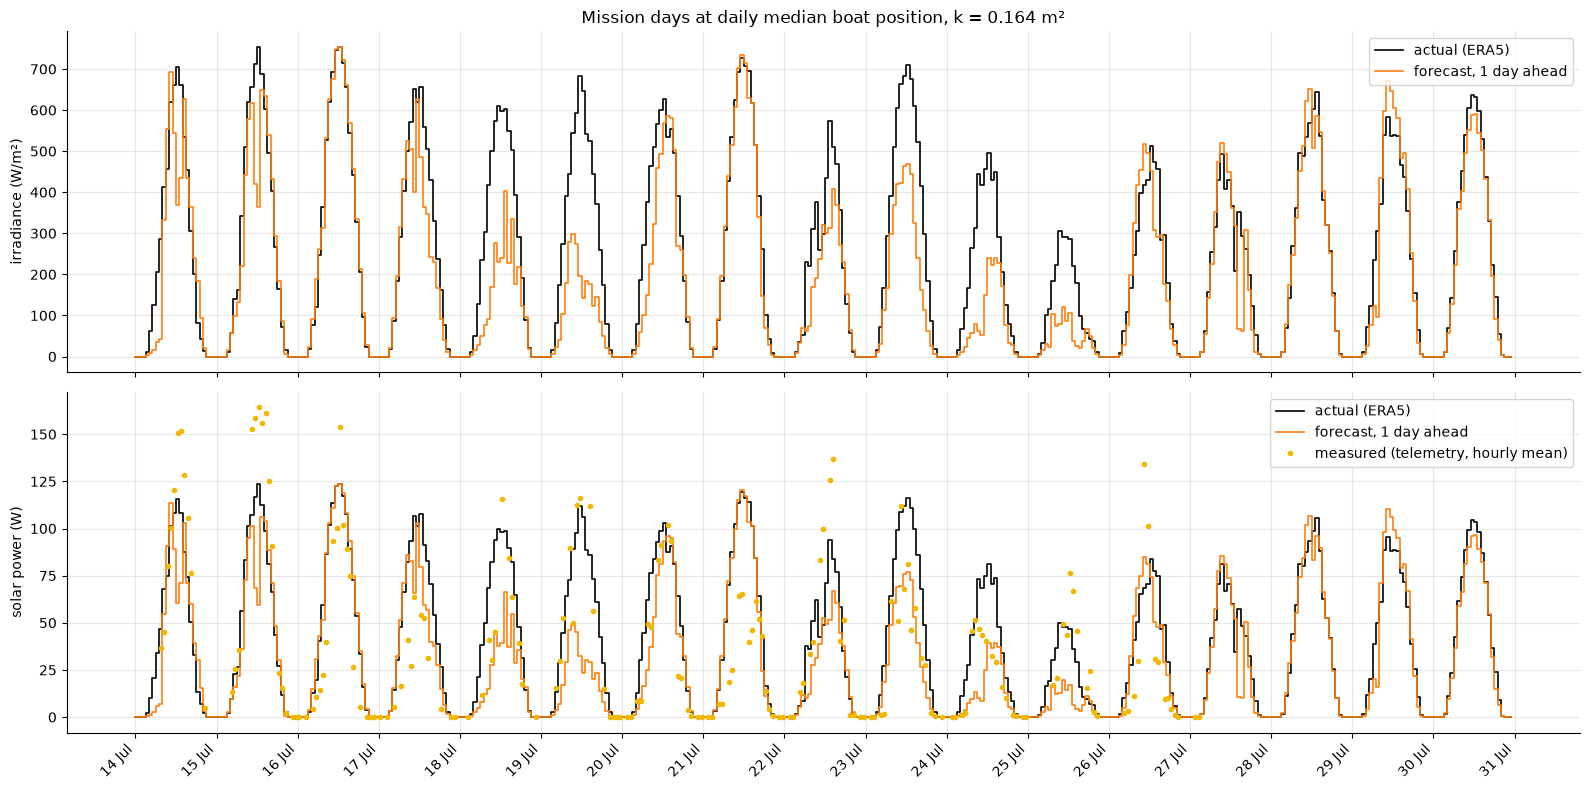

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
for ax, col, unit in [(ax1, "G", "irradiance (W/m²)"), (ax2, "P", "solar power (W)")]:
    ax.step(s.index, s[f"{col}_actual"], where="pre", color="k", lw=1.2, label="actual (ERA5)")
    ax.step(s.index, s[f"{col}_forecast"], where="pre", color="tab:orange", lw=1.2, label=f"forecast, {LEAD} day ahead")
    ax.set_ylabel(unit)
ax2.plot(s.index - pd.Timedelta("30min"), s.P_measured, "o", ms=3, color="#f2b701", label="measured (telemetry, hourly mean)")
ax1.legend(loc="upper right"); ax2.legend(loc="upper right")
ax1.set_title(f"Mission days at daily median boat position, k = {K} m²")
ax2.xaxis.set_major_locator(mdates.DayLocator())
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%d %b"))
plt.setp(ax2.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

**Per day:** solar energy (Wh) forecast vs actual (k × ERA5), and the error.

In [4]:
day = s.groupby(s.index.floor("D"))
daily = pd.DataFrame({"forecast_Wh": day.P_forecast.sum(), "actual_Wh": day.P_actual.sum()})
daily["error_Wh"] = daily.forecast_Wh - daily.actual_Wh
daily["error_%"] = 100 * daily.error_Wh / daily.actual_Wh
print(f"hourly power: mean error {s.err.mean():+.1f} W, RMSE {np.sqrt((s.err ** 2).mean()):.1f} W")
daily.set_axis(daily.index.strftime("%d %b")).round(0)

hourly power: mean error -8.4 W, RMSE 18.8 W


,forecast_Wh,actual_Wh,error_Wh,error_%
time,,,,
14 Jul,820.0,958.0,-138.0,-14.0
15 Jul,946.0,1093.0,-148.0,-14.0
16 Jul,1199.0,1177.0,21.0,2.0
17 Jul,835.0,1033.0,-197.0,-19.0
18 Jul,456.0,995.0,-539.0,-54.0
19 Jul,383.0,1026.0,-644.0,-63.0
20 Jul,808.0,1026.0,-218.0,-21.0
21 Jul,1098.0,1139.0,-41.0,-4.0
22 Jul,539.0,746.0,-207.0,-28.0
